In [1]:
import torch
from flow_matching.path import CondOTProbPath
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
from tqdm.auto import tqdm


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.2.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "/home/marco/miniforge3/envs/topoflow/lib/python3.10/runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "/home/marco/miniforge3/envs/topoflow/lib/python3.10/runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "/home/marco/miniforge3/envs/topoflow/lib/python3.10/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/home/marco/miniforge3/envs/topoflow/lib/python3.10/site-packages/traitlets/config/application.py",

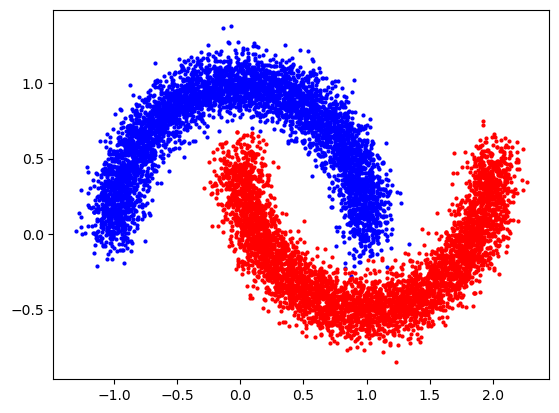

In [2]:
n_samples = 10000

data = make_moons(n_samples=n_samples, noise=0.1)
X_data = torch.tensor(data[0], dtype=torch.float32)
y_data = torch.tensor(data[1], dtype=torch.int64)
first_moon = data[0][data[1] == 0]
second_moon = data[0][data[1] == 1]

plt.plot(first_moon[:, 0], first_moon[:, 1], 'o', color='blue', markersize=2)
plt.plot(second_moon[:, 0], second_moon[:, 1], 'o', color='red', markersize=2)

In [6]:
class MLP(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(MLP, self).__init__()
        self.fc1 = torch.nn.Linear(input_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, output_dim)

    def forward(self, x, t):
        if len(x.shape) == 1:
            x = x.unsqueeze(0)
        if len(t.shape) == 0:
            t = t.unsqueeze(0)
        x = torch.cat([x, t.unsqueeze(1)], dim=1)
        x = torch.nn.functional.silu(self.fc1(x))
        x = self.fc2(x)
        return x

velocity_model = MLP(input_dim=3, hidden_dim=64, output_dim=2)
mse_loss = torch.nn.MSELoss()
optimizer = torch.optim.Adam(velocity_model.parameters(), lr=1e-3)

In [4]:
path = CondOTProbPath()

batch_size = 8

epochs = 100

progress_bar = tqdm(range(epochs), desc="Training", dynamic_ncols=True)

for epoch in progress_bar:
    epoch_loss = 0
    num_batches = n_samples // batch_size

    for i in range(num_batches):
        t = torch.rand(batch_size)
        x_0 = torch.randn(batch_size, 2)

        if not isinstance(X_data, torch.Tensor):
            X_data = torch.tensor(X_data, dtype=torch.float32)

        x_1 = X_data[torch.randint(0, n_samples, (batch_size,))]

        optimizer.zero_grad()

        path_sample = path.sample(x_0=x_0, x_1=x_1, t=t)

        loss = mse_loss(path_sample.dx_t, velocity_model(path_sample.x_t, t))

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_epoch_loss = epoch_loss / num_batches

    progress_bar.set_postfix(avg_loss=f"{avg_epoch_loss:.4f}")

Training:   0%|          | 0/100 [00:00<?, ?it/s]/home/marco/miniforge3/envs/topoflow/lib/python3.10/site-packages/torch/autograd/__init__.py:266: UserWarning: CUDA initialization: CUDA unknown error - this may be due to an incorrectly set up environment, e.g. changing env variable CUDA_VISIBLE_DEVICES after program start. Setting the available devices to be zero. (Triggered internally at /opt/conda/conda-bld/pytorch_1711403388920/work/c10/cuda/CUDAFunctions.cpp:108.)
  Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
Training: 100%|██████████| 100/100 [00:47<00:00,  2.10it/s, avg_loss=1.0424]


In [7]:
from flow_matching.solver import ODESolver

solver = ODESolver(velocity_model)

n_points = 1000
x_init = torch.randn(2)
step_size = 0.01
time_grid = torch.tensor([0.0, 1.0])

result = solver.sample(x_init=x_init, step_size=step_size, time_grid=time_grid)

In [12]:
path_sample.x_t.shape
# velocity_model(x_init, t)

torch.Size([8, 2])